# Which model version should go to production?

Your training pipeline registers a new `churn-classifier` version every time it runs.
Before one replaces production, someone has to answer: **is it actually better, and
can we trust how it was made?** That evidence is spread across the model registry,
pipeline runs and logs.

This notebook gathers it with the Kionga SDK and makes the decision explicit:

1. **Explore** every registered version against what's in production now.
2. **Trace** each candidate to the training run that produced it, and check that run's steps and logs.
3. **Apply promotion rules** you can read and change, with the reason any candidate fails.
4. **Decide and act:** promote the winner and archive the version it replaces, or explain why nothing qualifies.

Nothing changes until you set `PROMOTE = True`.

## Settings

Inside a Kionga notebook the client needs no configuration. Elsewhere, set
`KIONGA_URL` and a personal API key with the `models` and `pipelines` services in
`KIONGA_TOKEN`.

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import pandas as pd

from kionga import KiongaClient

MODEL_NAME = "churn-classifier"
PIPELINE_NAME = "training-pipeline"
METRIC = "auc"                 # the metric that decides
MIN_GAIN = 0.002               # a candidate must beat production by at least this much
MAX_AGE = timedelta(days=30)   # older versions are too stale to ship
PROMOTE = False                # set to True to promote the chosen version

client = KiongaClient()
now = datetime.now(timezone.utc)

## 1. Explore the registry

Every version of the model, oldest first. `gate` is the registry's own evaluation
gate; production can only take a version whose gate passed.

In [2]:
models = {m.id: m for m in client.list_models() if m.name == MODEL_NAME}
if not models:
    raise RuntimeError(f"No versions of {MODEL_NAME!r} are registered. Run {PIPELINE_NAME!r} first.")

registry = pd.DataFrame(
    {
        "version": m.version,
        "stage": m.stage,
        "gate": m.gate_status,
        **m.metrics,
        "registered": m.created_at,
        "age_days": round((now - m.created_at).total_seconds() / 86400, 1),
        "id": m.id,
    }
    for m in models.values()
).sort_values("registered").reset_index(drop=True)

production = next((m for m in models.values() if m.stage == "production"), None)
print(f"{len(registry)} versions registered; production:",
      f"version {production.version} ({METRIC} {production.metrics.get(METRIC)})" if production else "none yet")
registry

4 versions registered; production: none yet


,version,stage,gate,accuracy,auc,registered,age_days,id
0,1,candidate,passed,0.968,0.9891,2026-11-11 07:34:13.601535+00:00,0.3,mdl-1794382453601480536
1,2,candidate,passed,0.968,0.9891,2026-11-11 07:36:58.675313+00:00,0.3,mdl-1794382618675294422
2,3,candidate,passed,0.968,0.9891,2026-11-11 10:10:45.107163+00:00,0.2,mdl-1794391845107151814
3,4,staging,passed,0.968,0.9891,2026-11-11 10:11:03.660645+00:00,0.2,mdl-1794391863660643760


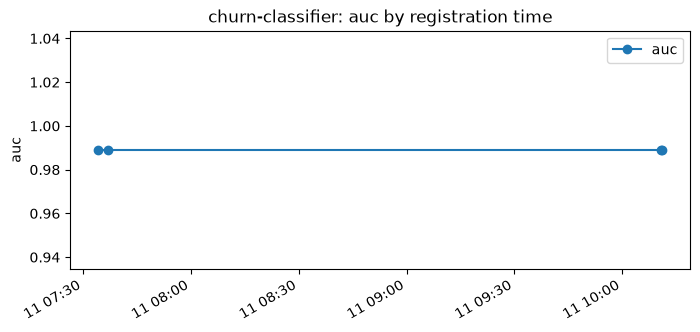

auc ranges over 0.0000 across 4 versions. The headline metric alone can't separate them.


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(registry["registered"], registry[METRIC], marker="o", label=METRIC)
if production is not None:
    ax.axhline(production.metrics[METRIC], color="tab:green", linestyle="--", label="production")
    ax.axhline(production.metrics[METRIC] + MIN_GAIN, color="tab:green", linestyle=":", label="required to replace it")
ax.set_title(f"{MODEL_NAME}: {METRIC} by registration time")
ax.set_ylabel(METRIC)
ax.legend()
fig.autofmt_xdate()
plt.show()

spread = registry[METRIC].max() - registry[METRIC].min()
print(f"{METRIC} ranges over {spread:.4f} across {len(registry)} versions."
      + (" The headline metric alone can't separate them." if spread < MIN_GAIN else ""))

## 2. Trace each version to its training run

A training run registers one model in its `register-model` step, so a model belongs
to the run whose time window contains its registration. Then the run's steps and
its warning and error log lines show whether training went cleanly.

In [4]:
runs = [r for r in client.list_pipeline_runs() if r.name == PIPELINE_NAME]


def training_run(model):
    matches = [r for r in runs if r.created_at <= model.created_at <= r.updated_at]
    return matches[0] if len(matches) == 1 else None


provenance = {}
for model in models.values():
    run = training_run(model)
    if run is None:
        provenance[model.id] = {"run": None, "steps_ok": False, "errors": None, "warnings": None, "retry_of": None}
        continue
    problems = client.query_logs(run_id=run.id, severities=["warn", "error"])
    provenance[model.id] = {
        "run": run.id,
        "steps_ok": run.status == "succeeded" and all(s.get("status") == "succeeded" for s in run.steps),
        "errors": sum(e.severity == "error" for e in problems),
        "warnings": sum(e.severity == "warn" for e in problems),
        "retry_of": run.parent_run_id or None,
    }

registry = registry.join(pd.DataFrame.from_dict(provenance, orient="index"), on="id")
registry[["version", "stage", "run", "steps_ok", "errors", "warnings", "retry_of"]]

,version,stage,run,steps_ok,errors,warnings,retry_of
0,1,candidate,run-1794382424693519164,True,0,0,None
1,2,candidate,run-1794382609347867000,True,0,0,None
2,3,candidate,run-1794391837343961493,True,0,0,None
3,4,staging,run-1794391855986568721,True,0,0,None


## 3. Apply the promotion rules

Each rule is one line, so you can change the policy and rerun. A candidate needs to
pass every rule; the table says which rules it failed.

In [5]:
baseline = production.metrics.get(METRIC) if production else None

RULES = {
    "evaluation gate passed": lambda row: row["gate"] == "passed",
    "traced to one training run": lambda row: row["run"] is not None,
    "every training step succeeded": lambda row: bool(row["steps_ok"]),
    "no errors in training logs": lambda row: row["errors"] == 0,
    f"registered in the last {MAX_AGE.days} days": lambda row: timedelta(days=row["age_days"]) <= MAX_AGE,
    f"has a {METRIC} score": lambda row: pd.notna(row.get(METRIC)),
    f"beats production by {MIN_GAIN}": lambda row: baseline is None or row[METRIC] >= baseline + MIN_GAIN,
}

candidates = registry[~registry["stage"].isin(["production", "archived"])].copy()
candidates["failed"] = candidates.apply(lambda row: [name for name, rule in RULES.items() if not rule(row)], axis=1)
candidates["eligible"] = candidates["failed"].str.len() == 0
candidates[["version", METRIC, "age_days", "eligible", "failed"]]

,version,auc,age_days,eligible,failed
0,1,0.9891,0.3,True,[]
1,2,0.9891,0.3,True,[]
2,3,0.9891,0.2,True,[]
3,4,0.9891,0.2,True,[]


## 4. Decide

Among eligible candidates the best score wins. On a tie, the newest version wins,
because it was trained on the current code and data.

In [6]:
eligible = candidates[candidates["eligible"]].sort_values([METRIC, "registered"], ascending=[False, False])

if eligible.empty:
    chosen = None
    print("No candidate qualifies, so production stays as it is. Most common reasons:")
    print(candidates["failed"].explode().value_counts().to_string())
else:
    chosen = models[eligible.iloc[0]["id"]]
    tied = eligible[eligible[METRIC] == eligible.iloc[0][METRIC]]
    print(f"Promote version {chosen.version} ({METRIC} {chosen.metrics[METRIC]}, registered {chosen.created_at:%Y-%m-%d %H:%M}).")
    if len(tied) > 1:
        print(f"{len(tied)} eligible versions tie on {METRIC}; the newest wins.")
    if production:
        print(f"It replaces version {production.version}, which will be archived.")

Promote version 4 (auc 0.9891, registered 2026-11-11 10:11).
4 eligible versions tie on auc; the newest wins.


## 5. Act

With `PROMOTE = False` this cell only reports what it would do. Set it to `True`
and rerun to promote. The old production version is archived so only one version
serves; the registry keeps it for rollback.

In [7]:
if chosen is None:
    print("Nothing to do.")
elif not PROMOTE:
    print(f"Dry run: would promote version {chosen.version}"
          + (f" and archive version {production.version}." if production else ".")
          + " Set PROMOTE = True and rerun this cell.")
else:
    promoted = client.promote_model(chosen.id, "production")
    print(f"Version {promoted.version} is now {promoted.stage} (was {promoted.previous_stage}).")
    if production and production.id != chosen.id:
        archived = client.promote_model(production.id, "archived")
        print(f"Version {archived.version} is now {archived.stage}.")
    # The registry records who changed what, for the review trail.
    changed = {chosen.id, getattr(production, "id", "")}
    trail = [e for e in client.audit_events() if e.resource_id in changed][:5]
    display(pd.DataFrame([e.model_dump(include={"created_at", "action", "resource_id", "actor"}) for e in trail]))

Dry run: would promote version 4. Set PROMOTE = True and rerun this cell.
